# Ejercicio Individual: Sandbox de Experimentación con Redes Neuronales

## Bootcamp Python - PY4
## Módulo 3: Deep Learning y NLP

---

### Identificación del Equipo

| Integrante | Rol |
|---|---|
| Jhonnatan Peñate | Arquitecto de Red / Especialista en Datos / Analista de Métricas |




## Antes de empezar: chequeo rápido de conceptos

**Pregunta:** ¿Cuál de las siguientes opciones describe correctamente, en orden, lo que sucede en una red neuronal durante un epoch de entrenamiento con mini-batches?

---

**Respuesta: B)**

Para cada batch: se calcula el forward pass, se mide el loss de ese batch, se calculan los gradientes con backpropagation, y el optimizador actualiza los pesos; esto se repite hasta recorrer todos los batches del dataset.

**Justificación:** En el entrenamiento con mini-batches, el ciclo no ocurre una sola vez por epoch sino una vez *por batch*. Cada iteración sigue el orden: forward pass → cálculo del loss → backpropagation → actualización de pesos. La opción A describe batch gradient descent puro (un solo update por epoch). La C invierte el orden (los pesos no se actualizan antes de calcular el forward pass). La D es incorrecta porque los weights se actualizan en cada epoch, no solo al inicio.

---

## 0. Preparando el entorno

In [1]:
# Importamos las librerias de manejo de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Importamos herramientas de preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer

# Importamos tensorflow y keras
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping

# Fijamos semillas para reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Entorno listo ✓")

TensorFlow version: 2.20.0
Entorno listo ✓


## 1. El dataset: Breast Cancer Wisconsin

In [2]:
# Cargamos el dataset desde scikit-learn
datos = load_breast_cancer()

# Lo convertimos a un DataFrame de pandas
X = pd.DataFrame(datos.data, columns=datos.feature_names)
y = pd.Series(datos.target, name="target")

# Importante: en este dataset, target=0 es maligno y target=1 es benigno
print("Clases:", dict(enumerate(datos.target_names)))

Clases: {0: np.str_('malignant'), 1: np.str_('benign')}


### Exploración del dataset

In [3]:
# Primeras filas de X
print("=== Primeras 5 filas ===")
display(X.head())

# Forma del dataset
print("\n=== Shape de X ===")
print(f"Filas: {X.shape[0]}, Columnas: {X.shape[1]}")

# Distribucion de clases
print("\n=== Distribución de clases en y ===")
conteo = y.value_counts()
print(f"Clase 0 (Maligno): {conteo[0]} ejemplos")
print(f"Clase 1 (Benigno): {conteo[1]} ejemplos")
print(f"Total: {len(y)} ejemplos")

=== Primeras 5 filas ===


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



=== Shape de X ===
Filas: 569, Columnas: 30

=== Distribución de clases en y ===
Clase 0 (Maligno): 212 ejemplos
Clase 1 (Benigno): 357 ejemplos
Total: 569 ejemplos


## 2. Preprocesamiento

In [4]:
# Dividimos los datos en train y test (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Creamos el scaler y lo ajustamos SOLO con train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Aplicamos el mismo scaler (sin re-ajustar) a test
X_test_scaled = scaler.transform(X_test)

# Guardamos la cantidad de features
n_features = X_train_scaled.shape[1]

print("Cantidad de features:", n_features)
print("Tamaño de train:", X_train_scaled.shape)
print("Tamaño de test:", X_test_scaled.shape)

Cantidad de features: 30
Tamaño de train: (455, 30)
Tamaño de test: (114, 30)


### Función para graficar las curvas de entrenamiento

In [5]:
def graficar_historia(history, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history["loss"], label="Entrenamiento")
    axes[0].plot(history.history["val_loss"], label="Validacion")
    axes[0].set_title(f"{titulo} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history.history["accuracy"], label="Entrenamiento")
    axes[1].plot(history.history["val_accuracy"], label="Validacion")
    axes[1].set_title(f"{titulo} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

## 3. Fase 1: Construcción de arquitecturas

### Modelo A — El Minimalista

**Decisión de diseño:** Una sola capa oculta de 8 neuronas. Es el modelo de referencia mínimo. Su baja capacidad lo hace poco propenso a overfitting, pero puede tener underfitting si el problema es complejo.

In [6]:
# Construccion del Modelo A
modelo_a = Sequential([
    Dense(8, activation="relu", input_shape=(n_features,)),
    Dense(1, activation="sigmoid")
], name="Modelo_A_Minimalista")

# Compilacion
modelo_a.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo_a.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Modelo_A_Minimalista"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │           248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257 (1.00 KB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Entrenamiento del Modelo A
history_a = modelo_a.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

print("Entrenamiento Modelo A completado ✓")

Entrenamiento Modelo A completado ✓


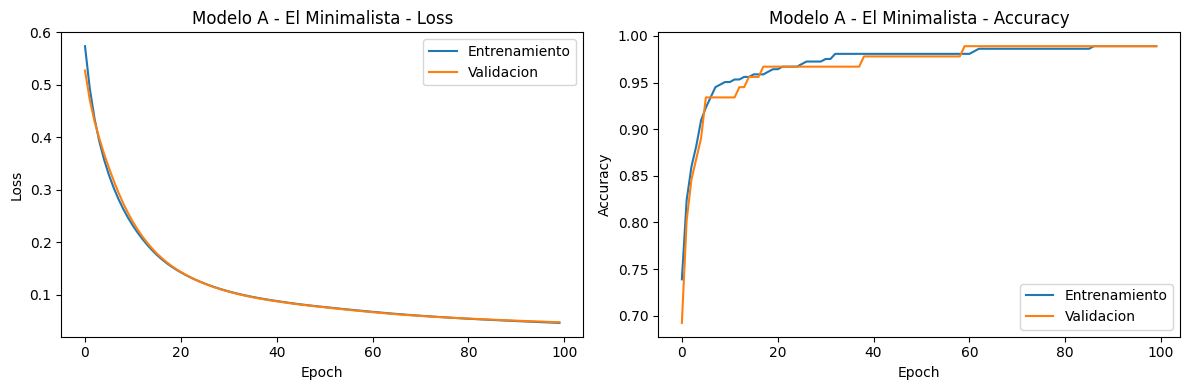

In [8]:
# Graficamos las curvas del Modelo A
graficar_historia(history_a, "Modelo A - El Minimalista")

### Modelo B — El Profundo

**Decisión de diseño:** Tres capas ocultas (64→32→16 neuronas). Mucha más capacidad de representación. Al tener más parámetros, es más susceptible a memorizar el training set (overfitting), especialmente sin regularización.

In [9]:
# Construccion del Modelo B
modelo_b = Sequential([
    Dense(64, activation="relu", input_shape=(n_features,)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
], name="Modelo_B_Profundo")

# Compilacion (misma config que Modelo A para comparacion justa)
modelo_b.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo_b.summary()

Model: "Modelo_B_Profundo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,609 (18.00 KB)

 Trainable params: 4,609 (18.00 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Entrenamiento del Modelo B
history_b = modelo_b.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

print("Entrenamiento Modelo B completado ✓")

Entrenamiento Modelo B completado ✓


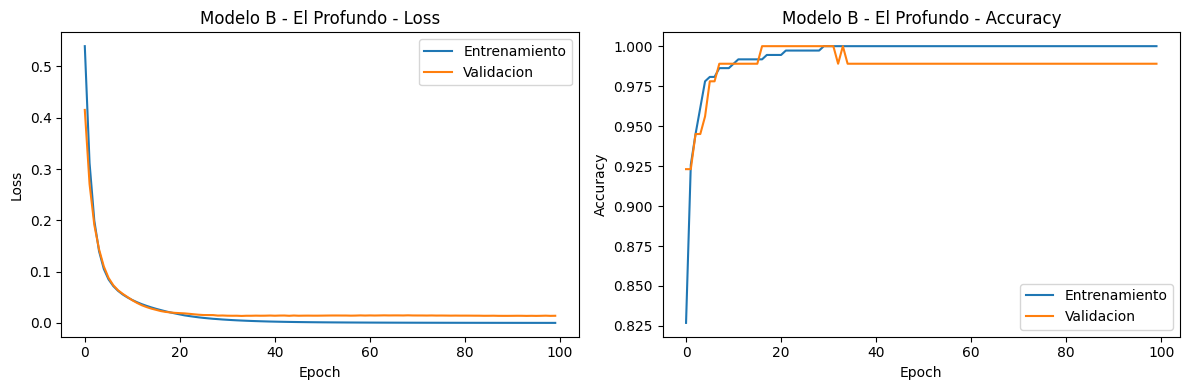

In [11]:
# Graficamos las curvas del Modelo B
graficar_historia(history_b, "Modelo B - El Profundo")

### Modelo C — El Optimizado

**Decisión de diseño:** Misma arquitectura profunda que B, pero con dos técnicas anti-overfitting:
- **Dropout(0.3):** Desactiva aleatoriamente el 30% de las neuronas en cada paso de entrenamiento, forzando que la red aprenda representaciones más robustas.
- **Regularización L2:** Penaliza los pesos grandes en la función de loss, evitando que la red memorice el ruido.
- **EarlyStopping:** Detiene el entrenamiento cuando `val_loss` deja de mejorar por 10 epochs consecutivos.

In [12]:
# Construccion del Modelo C con Dropout y regularizacion L2
modelo_c = Sequential([
    Dense(64, activation="relu", input_shape=(n_features,),
          kernel_regularizer=regularizers.l2(0.001)),
    Dropout(0.3),
    Dense(32, activation="relu",
          kernel_regularizer=regularizers.l2(0.001)),
    Dropout(0.3),
    Dense(16, activation="relu",
          kernel_regularizer=regularizers.l2(0.001)),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
], name="Modelo_C_Optimizado")

# Compilacion
modelo_c.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo_c.summary()

Model: "Modelo_C_Optimizado"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,609 (18.00 KB)

 Trainable params: 4,609 (18.00 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Definimos el callback de EarlyStopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Entrenamiento del Modelo C con EarlyStopping
history_c = modelo_c.fit(
    X_train_scaled, y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=0
)

print("Epochs efectivamente entrenados:", len(history_c.history["loss"]))

Epochs efectivamente entrenados: 85


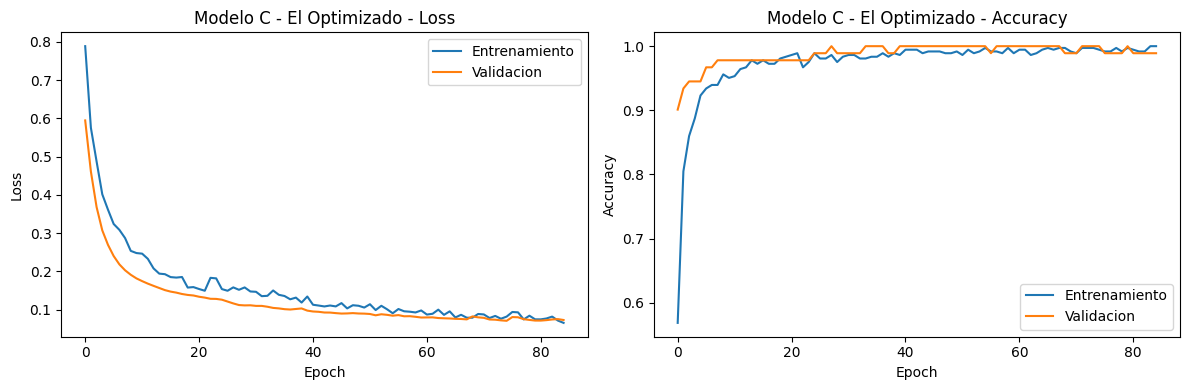

In [14]:
# Graficamos las curvas del Modelo C
graficar_historia(history_c, "Modelo C - El Optimizado")

## 4. Fase 2: Monitoreo y auditoría de resultados

### Comparando las curvas de val_loss

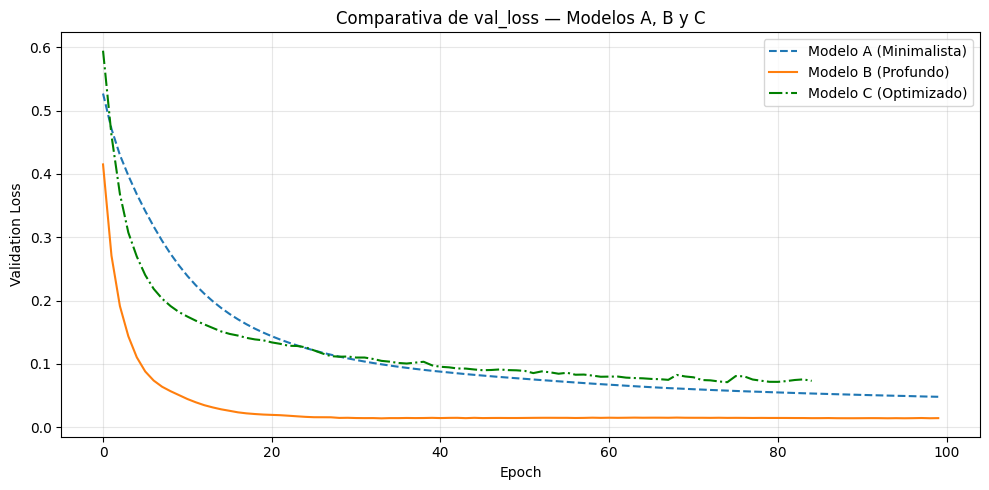

In [15]:
# Grafica comparativa del val_loss de los tres modelos
plt.figure(figsize=(10, 5))

plt.plot(history_a.history["val_loss"], label="Modelo A (Minimalista)", linestyle="--")
plt.plot(history_b.history["val_loss"], label="Modelo B (Profundo)", linestyle="-")
plt.plot(history_c.history["val_loss"], label="Modelo C (Optimizado)", linestyle="-.", color="green")

plt.title("Comparativa de val_loss — Modelos A, B y C")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Identificando el epoch de mejor val_loss

In [16]:
# Epoch con el val_loss mas bajo para cada modelo
mejor_epoch_a = np.argmin(history_a.history["val_loss"])
mejor_epoch_b = np.argmin(history_b.history["val_loss"])
mejor_epoch_c = np.argmin(history_c.history["val_loss"])

total_a = len(history_a.history["val_loss"])
total_b = len(history_b.history["val_loss"])
total_c = len(history_c.history["val_loss"])

print(f"Modelo A — Mejor val_loss en epoch {mejor_epoch_a+1} de {total_a} (overfitting desde epoch ~{mejor_epoch_a+1})")
print(f"Modelo B — Mejor val_loss en epoch {mejor_epoch_b+1} de {total_b} (overfitting desde epoch ~{mejor_epoch_b+1})")
print(f"Modelo C — Mejor val_loss en epoch {mejor_epoch_c+1} de {total_c} (EarlyStopping activo)")

Modelo A — Mejor val_loss en epoch 100 de 100 (overfitting desde epoch ~100)
Modelo B — Mejor val_loss en epoch 34 de 100 (overfitting desde epoch ~34)
Modelo C — Mejor val_loss en epoch 75 de 85 (EarlyStopping activo)



### Preguntas de reflexión

**1. Punto de overfitting.**

En el **Modelo A**, mirando la curva de loss, tanto entrenamiento como validación bajan juntas y se mantienen prácticamente pegadas durante todo el entrenamiento. No se ve un punto claro de overfitting, las dos curvas se unen y se estabilizan juntas cerca del epoch 60–70. Esto se da asi porque con solo 8 neuronas el modelo no tiene suficiente capacidad para memorizar el training set, entonces simplemente aprende lo que puede y se queda ahí.

En el **Modelo B**, el overfitting es mucho más facil de notar, ya que el `train_loss` baja hasta casi 0, mientras que el `val_loss` se separa y se queda estancado alrededor de 0.01–0.02. En la curva de la accuracy también se ve que el entrenamiento llega a 1.0 (100%) mientras que validación se estabiliza en ~0.988. Esa diferencia o brecha entre las dos curvas con el epoch ~20 en adelante signigica que esto se cnvirtio en overfitting y la red memorizó el training set pero no generaliza igual de bien.

El **Modelo C** fue diferernte ya que el `train_loss` queda *por encima* del `val_loss` durante casi todo el entrenamiento. Eso parece raro pero es normal con Dropout activo y durante el entrenamiento se desactivan neuronas aleatoriamente (lo que hace el loss más alto), pero en validación se usan todas las neuronas. El modelo C en este caso se detuvo en el epoch ~85 gracias a EarlyStopping y las dos curvas se unen o convergen sin mostrar una brecha tan significativa, lo que indica buena generalización en este caos.

---

**2. Capacidad vs generalización.**

El Modelo B tiene muchos más parámetros que el A (64→32→16 neuronas vs solo 8), y eso se nota. ya que convergió más rápido y llegó a un accuracy de entrenamiento casi perfecto. Sin embargo, en validación el Modelo A llegó a ~0.989 y el B a ~0.988 — prácticamente igual, con el A usando una fracción de los parámetros.

Esto significa que más parámetros sin regularización no implica mejor generalización. El Modelo B aprendió a ajustarse al ruido específico del training set (overfitting), mientras que el A, al tener poca capacidad, fue obligado a aprender solo los patrones más relevantes. Para este dataset en particular, la arquitectura simple fue suficiente.

---

**3. Funciones de activación y vanishing gradient.**

El vanishing gradient es un problema que ocurre durante la etapa del backpropagation eso sucede cuando la red aprende, los gradientes viajan de atrás hacia adelante (de la capa de salida hacia las capas iniciales) para actualizar los pesos. El problema con el `sigmoid` es que su derivada tiene un valor máximo de 0.25, entonces cada vez que el gradiente pasa por una capa, se multiplica por ese número pequeño y sigue y sigue repititendose. Y eso en una red profunda como el Modelo B (3 capas ocultas) ese gradiente se multiplica 3 veces: 0.25 × 0.25 × 0.25 = 0.015. Las primeras capas reciben un gradiente casi nulo y prácticamente no aprenden.

Con `relu` esto no pasa, porque su derivada es simplemente 1 para valores positivos. El gradiente viaja sin encogerse. En el Modelo A con solo 1 capa oculta, el problema sería menor de todas formas porque hay menos capas que atravesar — pero en el Modelo B y C, usar `relu` en lugar de `sigmoid` fue necesario para que las capas iniciales pudieran aprender correctamente.

---

**4. EarlyStopping.**

Mirando la gráfica del Modelo C, el entrenamiento se detuvo en el epoch ~85 (de los 150 que tenía como límite). Eso significa que EarlyStopping ahorró aproximadamente 65 epochs de entrenamiento innecesario.

Lo que hace o consiste su función el EarlyStopping es monitorear el `val_loss` en cada epoch y, si no mejora por 10 epochs seguidos (`patience=10`), detiene el entrenamiento. Con `restore_best_weights=True`, el modelo no se queda con los pesos del último epoch sino con los del epoch donde el `val_loss` fue más bajo — en este caso alrededor del epoch ~75. Sin ese callback, el modelo habría seguido entrenando hasta el epoch 150 posiblemente sobreajustándose, y el `val_loss` final hubiera sido peor que el mejor que encontró.

## 6. Tabla resumen final

In [17]:
# Evaluacion de los tres modelos sobre el conjunto de test
print("Evaluando modelos en test set...\n")

loss_a, acc_a = modelo_a.evaluate(X_test_scaled, y_test, verbose=0)
loss_b, acc_b = modelo_b.evaluate(X_test_scaled, y_test, verbose=0)
loss_c, acc_c = modelo_c.evaluate(X_test_scaled, y_test, verbose=0)

params_a = modelo_a.count_params()
params_b = modelo_b.count_params()
params_c = modelo_c.count_params()

epochs_efectivos_c = len(history_c.history["loss"])

# DataFrame comparativo
resumen = pd.DataFrame({
    "Modelo": ["A - Minimalista", "B - Profundo", "C - Optimizado"],
    "Test Loss": [round(loss_a, 4), round(loss_b, 4), round(loss_c, 4)],
    "Test Accuracy": [round(acc_a, 4), round(acc_b, 4), round(acc_c, 4)],
    "Parámetros": [params_a, params_b, params_c],
    "Epochs entrenados": [100, 100, epochs_efectivos_c]
})

print("=== Tabla Comparativa Final ===")
display(resumen)

mejor = resumen.loc[resumen["Test Accuracy"].idxmax(), "Modelo"]
print(f"\nMejor modelo en test accuracy: {mejor}")

Evaluando modelos en test set...

=== Tabla Comparativa Final ===


,Modelo,Test Loss,Test Accuracy,Parámetros,Epochs entrenados
0,A - Minimalista,0.0895,0.9737,257,100
1,B - Profundo,0.2245,0.9561,4609,100
2,C - Optimizado,0.2062,0.9649,4609,85



Mejor modelo en test accuracy: A - Minimalista


## Cierre y conclusiones

Lo que más me llamó la atención de este ejercicio fue ver como en las gráficas algo que en teoría suena tonto u obvio pero que no es lo mismo verlo en números que verlo visualmente: el Modelo A, con solo 8 neuronas, llegó prácticamente al mismo accuracy en validación que el Modelo B con tres capas y cientos de parámetros. Eso dice bastante sobre cómo funciona realmente el overfitting.

El Modelo B fue el más diferente e interesante de analizar porque la brecha entre entrenamiento y validación es clarísima en las curvas y el train_loss cae casi a 0 mientras que el val_loss se estanca. La red aprendió el training set de memoria, no los patrones reales. Sin regularizar esto a más profundidad solo amplifica ese problema.

El Modelo C fue el mas dificultoso de entender al inicio, porque la curva de entrenamiento queda por encima de la de validación, lo cual parece al revés y raro. Pero tiene sentido una vez que entendés que Dropout desactiva neuronas aleatoriamente durante el entrenamiento, haciendo el loss artifial sea más alto, mientras que en validación se usan todas. Eso en realidad es una buena señal, significa que el modelo no está memorizando.

La conclusión que me llevo es que diseñar una red neuronal no es solo apilar capas hasta que el accuracy suba. Es entender qué está pasando adentro en cada epoch, y saber cuándo parar.